**TASK 1: IRIS FLOWER CLASSIFICATION**

Import required libraries

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Load Iris Dataset

In [ ]:
# Load the Iris dataset

iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target species
df["species"] = iris.target
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display species names
print("\nFlower species:", iris.target_names)

# Display the number of samples per species
print("\nSpecies distribution:")
print(df["species_name"].value_counts())

First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



Dataset shape: (150, 6)

Flower species: ['setosa' 'versicolor' 'virginica']

Species distribution:
species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Explore the dataset

---



In [ ]:
# Display dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64


Visualize the data

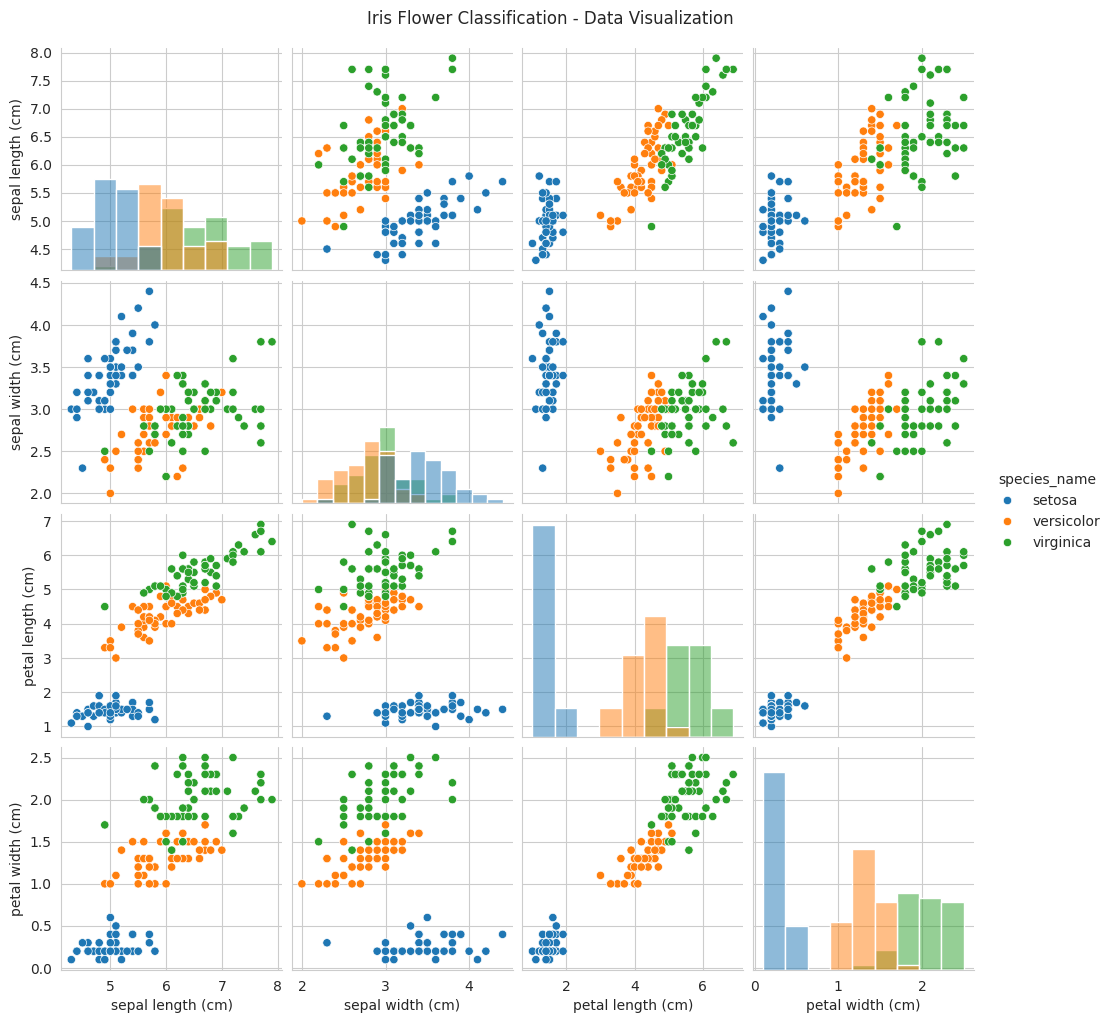

In [ ]:
# Set the visualization style
sns.set_style("whitegrid")

# Pairplot to compare all measurements
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species_name",
    diag_kind="hist"
)

plt.suptitle(
    "Iris Flower Classification - Data Visualization",
    y=1.02
)

plt.show()

Prepare the input and output data

In [ ]:
# Define input features
X = iris.data

# Define target labels
y = iris.target

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nFeature names:")
print(iris.feature_names)

print("\nTarget classes:")
print(iris.target_names)

Input data shape: (150, 4)
Target data shape: (150,)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa' 'versicolor' 'virginica']


Split the dataset into training and testing sets

In [ ]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


Standardize the features

In [ ]:
# Create a StandardScaler
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


Train the machine learning model

In [ ]:
# Create the KNN model
model = KNeighborsClassifier(n_neighbors=5)

# Train the model
model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


Make predictions

In [ ]:
# Predict the flower species
y_pred = model.predict(X_test_scaled)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Species": iris.target_names[y_test],
    "Predicted Species": iris.target_names[y_pred]
})

print("Actual vs Predicted Results:")
display(results)

Actual vs Predicted Results:


,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Evaluate model accuracy

In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy: {:.2f}%".format(accuracy * 100))

# Display classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Model Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



Display the confusion matrix

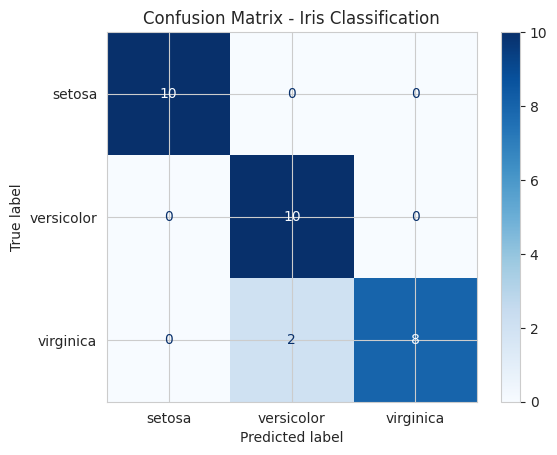

In [ ]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Iris Classification")
plt.show()

Predict a new flower

In [ ]:
# Example measurements for a new flower
# [sepal length, sepal width, petal length, petal width]

new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

# Scale the new flower using the existing scaler
new_flower_scaled = scaler.transform(new_flower)

# Predict the species
prediction = model.predict(new_flower_scaled)

# Get the species name
predicted_species = iris.target_names[prediction[0]]

print("New Flower Measurements:", new_flower[0])
print("Predicted Flower Species:", predicted_species.capitalize())

New Flower Measurements: [5.1 3.5 1.4 0.2]
Predicted Flower Species: Setosa


Display feature importance through visualization

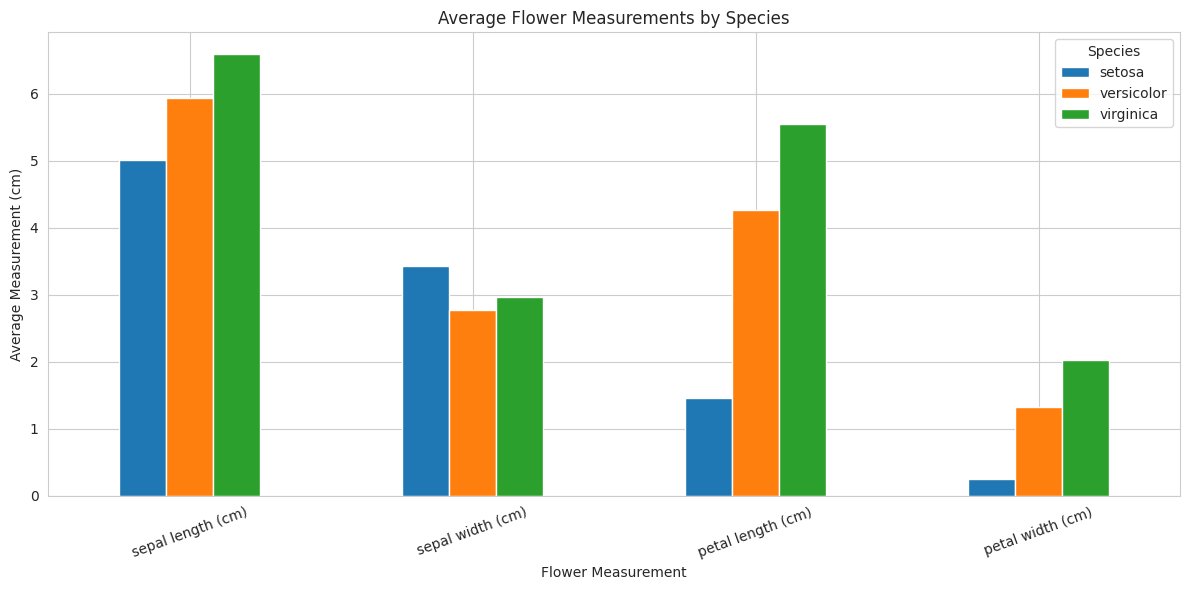

In [ ]:
# Calculate average measurements for each species
species_means = df.groupby("species_name")[
    iris.feature_names
].mean()

# Plot average measurements
species_means.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Flower Measurements by Species")
plt.xlabel("Flower Measurement")
plt.ylabel("Average Measurement (cm)")
plt.xticks(rotation=20)
plt.legend(title="Species")
plt.tight_layout()
plt.show()

Test multiple K values

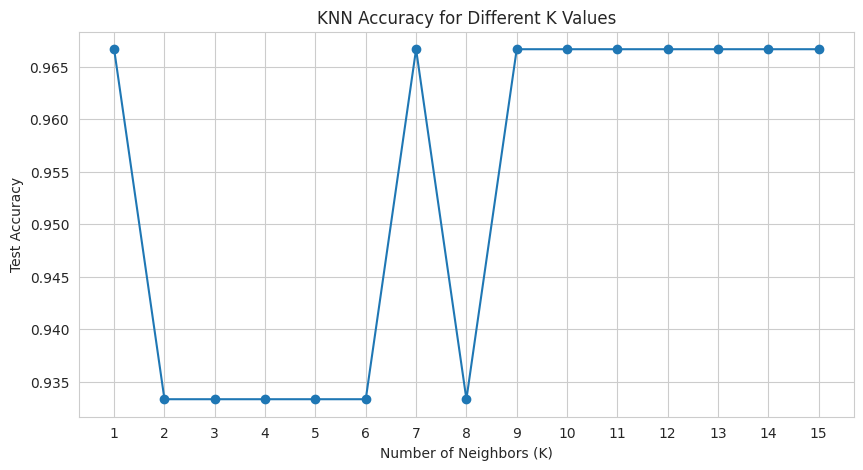

Best K value: 1
Best Test Accuracy: 96.67%


In [ ]:
# Compare different K values

k_values = range(1, 16)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    predictions = knn.predict(X_test_scaled)

    acc = accuracy_score(y_test, predictions)
    accuracies.append(acc)

# Plot accuracy for different K values
plt.figure(figsize=(10, 5))

plt.plot(
    list(k_values),
    accuracies,
    marker="o"
)

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Display the best K value for this test split
best_index = np.argmax(accuracies)
best_k = list(k_values)[best_index]
best_accuracy = accuracies[best_index]

print("Best K value:", best_k)
print("Best Test Accuracy: {:.2f}%".format(best_accuracy * 100))

Final project summary

In [ ]:
print("=" * 50)
print("IRIS FLOWER CLASSIFICATION PROJECT")
print("=" * 50)

print("\nDataset: Iris Flower Dataset")
print("Total Samples:", len(iris.data))
print("Number of Features:", iris.data.shape[1])
print("Flower Species:", ", ".join(iris.target_names))

print("\nAlgorithm: K-Nearest Neighbors (KNN)")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Accuracy: {:.2f}%".format(accuracy * 100))

print("\nProject completed successfully!")
print("=" * 50)

IRIS FLOWER CLASSIFICATION PROJECT

Dataset: Iris Flower Dataset
Total Samples: 150
Number of Features: 4
Flower Species: setosa, versicolor, virginica

Algorithm: K-Nearest Neighbors (KNN)
Training Samples: 120
Testing Samples: 30
Model Accuracy: 93.33%

Project completed successfully!
